EXPLORASI DAN PEMAHAMAN DATA SERTA PRAPROSES DATA GROCERIES_DATASET

mencakup pemeriksaan data, EDA, visualisasi, pemeriksaan kualitas data, dan pembentukan data transaksi dalam format one-hot encoding

In [ ]:
# 1. IMPORT LIBRARY
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

# Menampilkan seluruh kolom saat diperlukan
pd.set_option("display.max_columns", None)

In [ ]:
# 2. MEMBACA DATASET
DATA_PATH = "../content/Groceries_dataset.csv"
df = pd.read_csv(DATA_PATH)
print("Lima Data Pertama:")
display(df.head())

print("Lima Data Terakhir:")
display(df.tail())

Lima Data Pertama:


,Member_number,Date,itemDescription
0,1808,21-07-2015,tropical fruit
1,2552,05-01-2015,whole milk
2,2300,19-09-2015,pip fruit
3,1187,12-12-2015,other vegetables
4,3037,01-02-2015,whole milk


Lima Data Terakhir:


,Member_number,Date,itemDescription
38760,4471,08-10-2014,sliced cheese
38761,2022,23-02-2014,candy
38762,1097,16-04-2014,cake bar
38763,1510,03-12-2014,fruit/vegetable juice
38764,1521,26-12-2014,cat food


In [ ]:
# 3. PEMERIKSAAN KUALITAS DATA
print("Ukuran Dataset:", df.shape)

print("\nInformasi Dataset:")
df.info()

print("\nJumlah Missing Value:", df.isnull().sum())
print("Baris duplikat penuh :", df.duplicated().sum())
print("Pelanggan unik       :", df["Member_number"].nunique())
print("Tanggal unik         :", df["Date"].nunique())
print("Produk unik          :", df["itemDescription"].nunique())

Ukuran Dataset: (38765, 3)

Informasi Dataset:
<class 'pandas.DataFrame'>
RangeIndex: 38765 entries, 0 to 38764
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Member_number    38765 non-null  int64
 1   Date             38765 non-null  str  
 2   itemDescription  38765 non-null  str  
dtypes: int64(1), str(2)
memory usage: 1.6 MB

Jumlah Missing Value: Member_number      0
Date               0
itemDescription    0
dtype: int64
Baris duplikat penuh : 759
Pelanggan unik       : 3898
Tanggal unik         : 728
Produk unik          : 167


In [ ]:
# 4. MELIHAT TIPE DATA
df.dtypes

Member_number      int64
Date                 str
itemDescription      str
dtype: object

In [ ]:
# 5. KLASIFIKASI TIPE DATA SEMANTIK
klasifikasi = pd.DataFrame({
    "Kolom": df.columns,
    "Tipe Teknis": df.dtypes.astype(str).values,
    "Tipe Semantik": [
        "Identifier (ID pelanggan)",
        "Tanggal (Date)",
        "Kategorikal Nominal (Nama produk)"
    ],
    "Keterangan": [
        "Identitas pelanggan yang melakukan transaksi",
        "Menunjukkan tanggal transaksi",
        "Menunjukkan produk yang dibeli"
    ]
})

display(klasifikasi)

,Kolom,Tipe Teknis,Tipe Semantik,Keterangan
0,Member_number,int64,Identifier (ID pelanggan),Identitas pelanggan yang melakukan transaksi
1,Date,str,Tanggal (Date),Menunjukkan tanggal transaksi
2,itemDescription,str,Kategorikal Nominal (Nama produk),Menunjukkan produk yang dibeli


PENYESUAIAN TIPE DATA DAN PEMBENTUKAN TRANSAKSI

Dataset tidak menyediakan ID transaksi secara langsung. Pada analisis ini, transaksi dibentuk menggunakan kombinasi **Member_number dan Date**.

Artinya, seluruh produk yang dicatat untuk pelanggan yang sama pada tanggal yang sama dianggap sebagai satu transaksi.

In [ ]:
# 6. KONVERSI DATE KE DATETIME
# AWALNYA FORMAT TANGGAL BERBERDA BEDA
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

print("Tipe Data Setelah Penyesuaian:")
print(df.dtypes)

print("\nJumlah Tanggal Tidak Valid:")
print(df["Date"].isnull().sum())

Tipe Data Setelah Penyesuaian:
Member_number               int64
Date               datetime64[us]
itemDescription               str
dtype: object

Jumlah Tanggal Tidak Valid:
0


In [ ]:
# 7. HITUNG JUMLAH TRANSAKSI DAN PRODUK SERTA BUAT ID TRANSAKSI
df["transaction_id"] = (
    df["Member_number"].astype("Int64").astype(str) + "_" +
    df["Date"].dt.strftime("%Y-%m-%d")
)

print("Jumlah baris data:", len(df))
print("Jumlah pelanggan unik:", df["Member_number"].nunique())
print("Jumlah tanggal unik:", df["Date"].nunique())
print("Jumlah produk unik:", df["itemDescription"].nunique())
print("Jumlah transaksi:", df["transaction_id"].nunique())

Jumlah baris data: 38765
Jumlah pelanggan unik: 3898
Jumlah tanggal unik: 728
Jumlah produk unik: 167
Jumlah transaksi: 14963


EKSPLORASI DATA (EDA)

In [ ]:
# 8. HITUNG JUMLAH PRODUK PER TRANSAKSI
# menggunakan jumlah produk unik agar pendatatan produk yang sama dalam satu transaksi tidak dihitung berulang dan membuat basket menjadi lebih besar.
basket_size = df.groupby("transaction_id")["itemDescription"].nunique()

print("Statistik ukuran basket:")
display(basket_size.describe())

Statistik ukuran basket:


count    14963.000000
mean         2.539999
std          1.060993
min          1.000000
25%          2.000000
50%          2.000000
75%          3.000000
max         10.000000
Name: itemDescription, dtype: float64

In [ ]:
# 9. HITUNG FREKUENSI PRODUK
frekuensi_produk = df["itemDescription"].value_counts()

print("10 Produk Paling Sering Dibeli:")
display(frekuensi_produk.head(10))

print("\n10 Produk Paling Jarang Dibeli:")
display(frekuensi_produk.tail(10))

print("Jumlah produk unik:", len(frekuensi_produk))

10 Produk Paling Sering Dibeli:


itemDescription
whole milk          2502
other vegetables    1898
rolls/buns          1716
soda                1514
yogurt              1334
root vegetables     1071
tropical fruit      1032
bottled water        933
sausage              924
citrus fruit         812
Name: count, dtype: int64


10 Produk Paling Jarang Dibeli:


itemDescription
whisky                   8
salad dressing           6
frozen chicken           5
rubbing alcohol          5
make up remover          5
toilet cleaner           5
bags                     4
baby cosmetics           3
kitchen utensil          1
preservation products    1
Name: count, dtype: int64

Jumlah produk unik: 167


In [ ]:
# 10. STATISTIK DISTRIBUSI UKURAN BASKET
print("Mean:", basket_size.mean())
print("Median:", basket_size.median())
print("Modus:", basket_size.mode().tolist())
print("Minimum:", basket_size.min())
print("Maksimum:", basket_size.max())
print("Range:", basket_size.max() - basket_size.min())
print("Variance:", basket_size.var())
print("Standard Deviation:", basket_size.std())

Q1 = basket_size.quantile(0.25)
Q3 = basket_size.quantile(0.75)
IQR = Q3 - Q1

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Skewness:", basket_size.skew())


Mean: 2.539998663369645
Median: 2.0
Modus: [2]
Minimum: 1
Maksimum: 10
Range: 9
Variance: 1.1257058414632581
Standard Deviation: 1.060992856461936
Q1: 2.0
Q3: 3.0
IQR: 1.0
Skewness: 2.5485408661029814


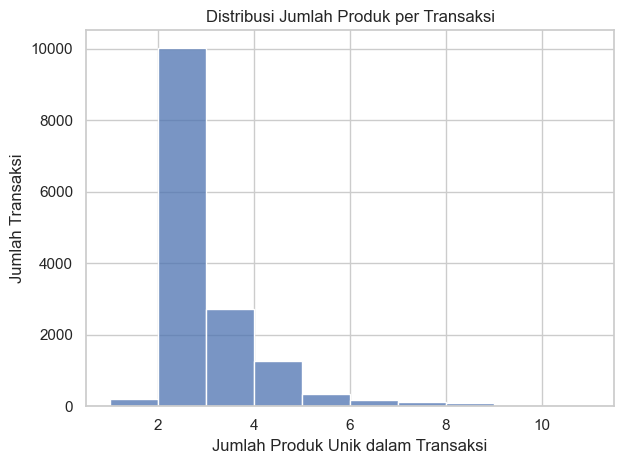

In [ ]:
# 11. VISUALISASI DISTRIBUSI UKURAN BASKET
sns.histplot(basket_size, bins=range(int(basket_size.min()), int(basket_size.max()) + 2), kde=False)
plt.title("Distribusi Jumlah Produk per Transaksi")
plt.xlabel("Jumlah Produk Unik dalam Transaksi")
plt.ylabel("Jumlah Transaksi")
plt.tight_layout()
plt.show()

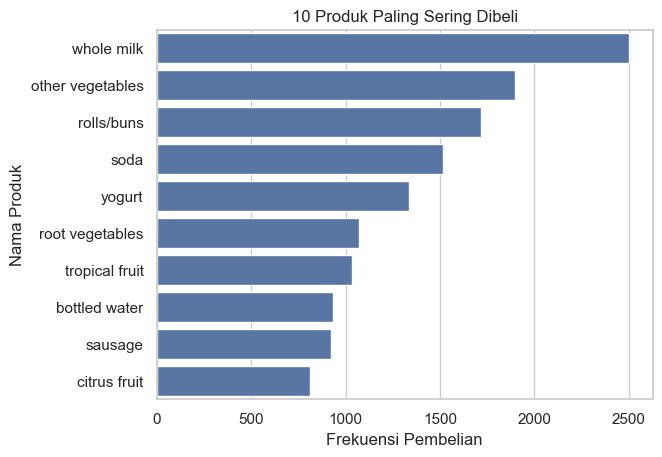

In [ ]:
# 12. VISUALISASI 10 PRODUK BEST SELLER
top_produk = frekuensi_produk.head(10)

sns.barplot(
    x=top_produk.values,
    y=top_produk.index
)

plt.title("10 Produk Paling Sering Dibeli")
plt.xlabel("Frekuensi Pembelian")
plt.ylabel("Nama Produk")
plt.show()

In [ ]:
# 13. HUBUNGAN JUMLAH PRODUK DAN FREKUENSI TRANSAKSI
distribusi_basket = basket_size.value_counts().sort_index()

display(
    distribusi_basket.rename_axis("Jumlah Produk").reset_index(
        name="Jumlah Transaksi"
    )
)

,Jumlah Produk,Jumlah Transaksi
0,1,205
1,2,10012
2,3,2727
3,4,1273
4,5,338
5,6,179
6,7,113
7,8,96
8,9,19
9,10,1


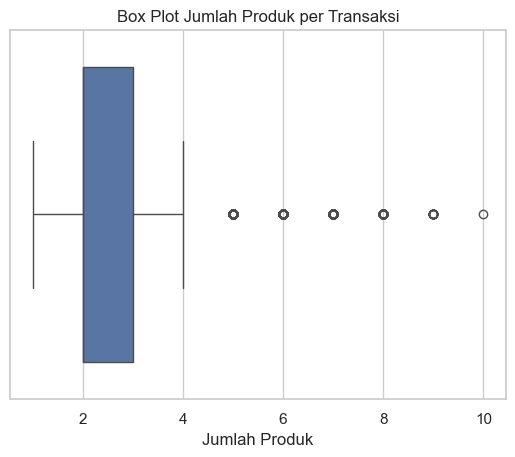

In [ ]:
# 14. BLOX PLOT UKURAN BASKET
sns.boxplot(x=basket_size)

plt.title("Box Plot Jumlah Produk per Transaksi")
plt.xlabel("Jumlah Produk")
plt.show()

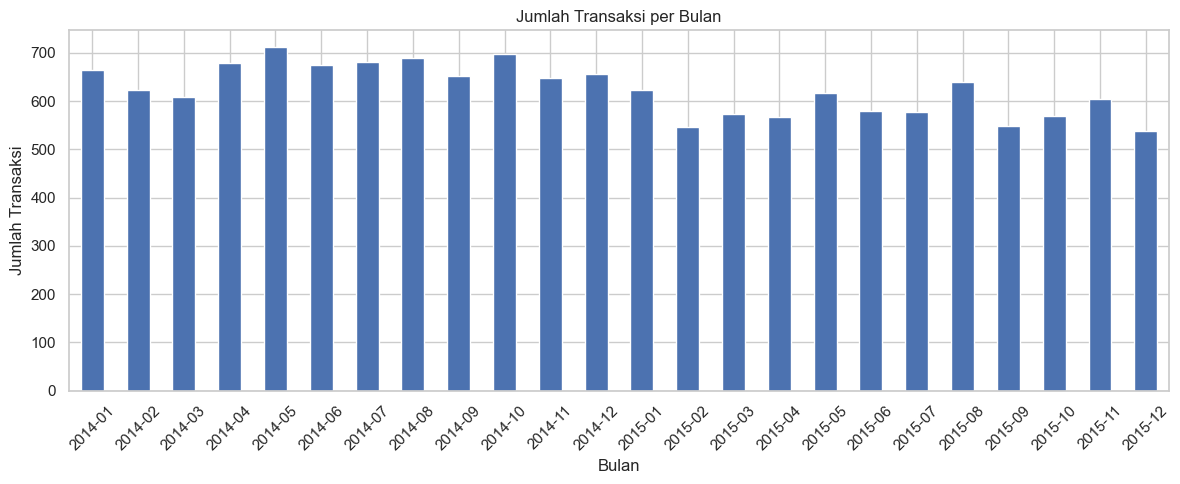

In [ ]:
# 15. BAR CHART JLH TRANSAKSI PER BULAN
transaksi_bulanan = (
    df.groupby(df["Date"].dt.to_period("M"))["transaction_id"]
    .nunique()
)

transaksi_bulanan.index = transaksi_bulanan.index.astype(str)

transaksi_bulanan.plot(kind="bar", figsize=(12, 5))

plt.title("Jumlah Transaksi per Bulan")
plt.xlabel("Bulan")
plt.ylabel("Jumlah Transaksi")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

PEMERIKSAAN KUALITAS DATA

In [ ]:
# 16. MISSING VALUES DAN NILAI TIDAK VALID
print("Missing values per kolom:")
print(df.isnull().sum())
print(
      "\nNama produk kosong atau hanya spasi:",
      df["itemDescription"].fillna("").astype(str).str.strip().eq("").sum()
)
print("Tanggal tidak valid:", df["Date"].isnull().sum())
print("ID pelanggan kosong:", df["Member_number"].isnull().sum())


Missing values per kolom:
Member_number      0
Date               0
itemDescription    0
transaction_id     0
dtype: int64

Nama produk kosong atau hanya spasi: 0
Tanggal tidak valid: 0
ID pelanggan kosong: 0


In [ ]:
# 17. DUPLIKAT DATA
print("Jumlah Baris Duplikat:")
print(df.duplicated().sum())

print("\nContoh Baris Duplikat:")
display(df[df.duplicated(keep=False)].head(10))

Jumlah Baris Duplikat:
759

Contoh Baris Duplikat:


,Member_number,Date,itemDescription,transaction_id
63,1663,2015-02-07,rolls/buns,1663_2015-02-07
98,3645,2015-12-12,citrus fruit,3645_2015-12-12
129,3779,2015-09-15,frankfurter,3779_2015-09-15
213,3812,2015-07-21,sausage,3812_2015-07-21
216,1344,2015-09-04,bottled water,1344_2015-09-04
256,2353,2015-05-02,soda,2353_2015-05-02
309,4899,2015-03-12,chicken,4899_2015-03-12
353,3929,2015-04-28,root vegetables,3929_2015-04-28
375,3967,2015-11-23,whole milk,3967_2015-11-23
437,2435,2015-07-17,onions,2435_2015-07-17


In [ ]:
# 18. DETEKSI OUTLIER DENGAN IQR
Q1 = basket_size.quantile(0.25)
Q3 = basket_size.quantile(0.75)

IQR = Q3 - Q1

batas_bawah = Q1 - 1.5 * IQR
batas_atas = Q3 + 1.5 * IQR

outlier = basket_size[
    (basket_size < batas_bawah) |
    (basket_size > batas_atas)
]

print("Batas Bawah:", batas_bawah)
print("Batas Atas:", batas_atas)
print("Jumlah Outlier:", len(outlier))

display(outlier.head(10))
print("Catatan: outlier hanya diidentifikasi, tidak otomatis dihapus karena transaksi besar belum tentu merupakan kesalahan data.")


Batas Bawah: 0.5
Batas Atas: 4.5
Jumlah Outlier: 746


transaction_id
1006_2015-06-14    7
1008_2015-07-21    7
1011_2015-12-09    7
1012_2015-11-19    5
1016_2015-09-30    5
1026_2015-03-15    5
1032_2015-06-15    6
1038_2015-02-21    5
1051_2015-10-12    5
1052_2015-10-27    6
Name: itemDescription, dtype: int64

Catatan: outlier hanya diidentifikasi, tidak otomatis dihapus karena transaksi besar belum tentu merupakan kesalahan data.


In [ ]:
# 19. PEMERIKSAAN KONSISTENSI NAMA PRODUK
produk_asli = df["itemDescription"].dropna().astype(str)
produk_normalisasi = produk_asli.str.strip().str.lower()
print("Jumlah nama produk unik sebelum normalisasi:", produk_asli.nunique())
print("Jumlah nama produk unik setelah normalisasi:", produk_normalisasi.nunique())
print("Contoh nama produk:")
display(pd.Series(produk_normalisasi.unique(), name="Nama Produk"))

Jumlah nama produk unik sebelum normalisasi: 167
Jumlah nama produk unik setelah normalisasi: 167
Contoh nama produk:


0             tropical fruit
1                 whole milk
2                  pip fruit
3           other vegetables
4                 rolls/buns
               ...          
162           pudding powder
163              ready soups
164          make up remover
165           toilet cleaner
166    preservation products
Name: Nama Produk, Length: 167, dtype: str

In [ ]:
# 20. RINGKASAN PEMERIKSAAN KUALITAS DATA
checklist = pd.DataFrame({
    "Pemeriksaan": [
        "Missing Values",
        "Data Duplikat",
        "Tanggal tidak valid",
        "Nama produk kosong/spasi",
        "Outlier Ukuran Basket",
        "Produk setelah normalisasi",
        "Tipe Data",
        "Nilai Tidak Valid"
    ],
    "Hasil": [
        df.isnull().sum().sum(),
        df.duplicated().sum(),
        int(df["Date"].isna().sum()),
        int(df["itemDescription"].fillna("").astype(str).str.strip().eq("").sum()),
        len(outlier),
        df["itemDescription"].nunique(),
        df.dtypes.astype(str).to_dict(),
        (
            (df["itemDescription"].astype(str).str.strip() == "").sum()
            + df["Date"].isnull().sum()
        )
    ]
})

display(checklist)

,Pemeriksaan,Hasil
0,Missing Values,0
1,Data Duplikat,759
2,Tanggal tidak valid,0
3,Nama produk kosong/spasi,0
4,Outlier Ukuran Basket,746
5,Produk setelah normalisasi,167
6,Tipe Data,"{'Member_number': 'int64', 'Date': 'datetime64..."
7,Nilai Tidak Valid,0


In [ ]:
# 21. SALIN DATASET
df_bersih = df.copy()

print("Ukuran Dataset Awal:", df_bersih.shape)

Ukuran Dataset Awal: (38765, 4)


PREPROSESSING DATA

In [ ]:
# 21. MENYALIN DATASET DAN MENANGANI NILAI KOSONG/TIDAK VALID
df_bersih = df.copy()

df_bersih = df_bersih.dropna(subset=["Member_number", "Date", "itemDescription"])
df_bersih["itemDescription"] = df_bersih["itemDescription"].astype(str).str.strip().str.lower()
df_bersih = df_bersih[df_bersih["itemDescription"] != ""]

print("Jumlah baris awal:", df_bersih.shape[0])
print("Jumlah baris setelah menghapus nilai kosong/tidak valid:", len(df_bersih))

Jumlah baris awal: 38765
Jumlah baris setelah menghapus nilai kosong/tidak valid: 38765


In [ ]:
# 22. MEMBENTUK ID TRANSAKSI DAN MENGHAPUS ITEM DUPLIKAT DALAM TRANSAKSI
# Membuat ulang ID transaksi
df_bersih["transaction_id"] = (
    df_bersih["Member_number"].astype(str) + "_" +
    df_bersih["Date"].dt.strftime("%Y-%m-%d")
)

# Menghapus pencatatan produk yang sama dalam transaksi yang sama
df_bersih = df_bersih.drop_duplicates(
    subset=["transaction_id", "itemDescription"]
)

print("Ukuran Dataset Setelah Pembersihan:")
print(df_bersih.shape)

print("\nJumlah Produk Unik:")
print(df_bersih["itemDescription"].nunique())

print("\nJumlah Transaksi:")
print(df_bersih["transaction_id"].nunique())

Ukuran Dataset Setelah Pembersihan:
(38006, 4)

Jumlah Produk Unik:
167

Jumlah Transaksi:
14963


In [ ]:
# 23. MEMBENTUK DAFTAR PRODUK PER TRANSAKSI
transactions = (
    df_bersih.groupby("transaction_id")["itemDescription"]
    .apply(list)
)

print("Jumlah transaksi sebelum penyaringan:", len(transactions))
print("Contoh 5 transaksi:")
for nomor, item in enumerate(transactions.head(5), start=1):
    print(f"Transaksi {nomor}: {item}")

Jumlah transaksi sebelum penyaringan: 14963
Contoh 5 transaksi:
Transaksi 1: ['whole milk', 'pastry', 'salty snack']
Transaksi 2: ['sausage', 'whole milk', 'semi-finished bread', 'yogurt']
Transaksi 3: ['soda', 'pickled vegetables']
Transaksi 4: ['canned beer', 'misc. beverages']
Transaksi 5: ['sausage', 'hygiene articles']


In [ ]:
# 24. MENGHAPUS TRANSAKSI DENGAN SATU PRODUK
jumlah_sebelum = len(transactions)
transactions = transactions[transactions.apply(len) > 1]
jumlah_sesudah = len(transactions)

print("Transaksi sebelum penyaringan:", jumlah_sebelum)
print("Transaksi setelah penyaringan:", jumlah_sesudah)
print("Transaksi satu produk yang dihapus:", jumlah_sebelum - jumlah_sesudah)

Transaksi sebelum penyaringan: 14963
Transaksi setelah penyaringan: 14758
Transaksi satu produk yang dihapus: 205


In [ ]:
# 25. MEMBUAT DATA ONE-HOT ENCODING
# Hanya mengambil baris yang termasuk transaksi dengan lebih dari satu produk.
df_model = df_bersih[df_bersih["transaction_id"].isin(transactions.index)].copy()

basket = pd.crosstab(
    index=df_model["transaction_id"],
    columns=df_model["itemDescription"]
)
basket = (basket > 0).astype(int)

print("Ukuran data one-hot encoding:", basket.shape)
display(basket.head())
print("1 = produk terdapat dalam transaksi")
print("0 = produk tidak terdapat dalam transaksi")

Ukuran data one-hot encoding: (14758, 167)


itemDescription,abrasive cleaner,artif. sweetener,baby cosmetics,bags,baking powder,bathroom cleaner,beef,berries,beverages,bottled beer,bottled water,brandy,brown bread,butter,butter milk,cake bar,candles,candy,canned beer,canned fish,canned fruit,canned vegetables,cat food,cereals,chewing gum,chicken,chocolate,chocolate marshmallow,citrus fruit,cleaner,cling film/bags,cocoa drinks,coffee,condensed milk,cooking chocolate,cookware,cream,cream cheese,curd,curd cheese,decalcifier,dental care,dessert,detergent,dish cleaner,dishes,dog food,domestic eggs,female sanitary products,finished products,fish,flour,flower (seeds),flower soil/fertilizer,frankfurter,frozen chicken,frozen dessert,frozen fish,frozen fruits,frozen meals,frozen potato products,frozen vegetables,fruit/vegetable juice,grapes,hair spray,ham,hamburger meat,hard cheese,herbs,honey,house keeping products,hygiene articles,ice cream,instant coffee,instant food products,jam,ketchup,kitchen towels,kitchen utensil,light bulbs,liqueur,liquor,liquor (appetizer),liver loaf,long life bakery product,make up remover,male cosmetics,margarine,mayonnaise,meat,meat spreads,misc. beverages,mustard,napkins,newspapers,nut snack,nuts/prunes,oil,onions,organic products,organic sausage,other vegetables,packaged fruit/vegetables,pasta,pastry,pet care,photo/film,pickled vegetables,pip fruit,popcorn,pork,pot plants,potato products,preservation products,processed cheese,prosecco,pudding powder,ready soups,red/blush wine,rice,roll products,rolls/buns,root vegetables,rubbing alcohol,rum,salad dressing,salt,salty snack,sauces,sausage,seasonal products,semi-finished bread,shopping bags,skin care,sliced cheese,snack products,soap,soda,soft cheese,softener,soups,sparkling wine,specialty bar,specialty cheese,specialty chocolate,specialty fat,specialty vegetables,spices,spread cheese,sugar,sweet spreads,syrup,tea,tidbits,toilet cleaner,tropical fruit,turkey,uht-milk,vinegar,waffles,whipped/sour cream,whisky,white bread,white wine,whole milk,yogurt,zwieback
transaction_id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1000_2014-06-24,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0
1000_2015-03-15,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0
1000_2015-05-27,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1000_2015-07-24,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1000_2015-11-25,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


1 = produk terdapat dalam transaksi
0 = produk tidak terdapat dalam transaksi


In [ ]:
# 26. MEMERIKSA HASIL ONE-HOT ENCODING
print("Jumlah transaksi:", basket.shape[0])
print("Jumlah produk:", basket.shape[1])
print("\nJumlah item pada 5 transaksi pertama:")
print(basket.sum(axis=1).head())
print("\nHasil nilai encoding:")
print(basket.stack().value_counts())

Jumlah transaksi: 14758
Jumlah produk: 167

Jumlah item pada 5 transaksi pertama:
transaction_id
1000_2014-06-24    3
1000_2015-03-15    4
1000_2015-05-27    2
1000_2015-07-24    2
1000_2015-11-25    2
dtype: int64

Hasil nilai encoding:
0    2426785
1      37801
Name: count, dtype: int64


In [ ]:
# 27. FREKUENSI PRODUK SETELAH PREPROCESSING
frekuensi_encoding = basket.sum().sort_values(ascending=False)
print("10 produk paling sering muncul dalam transaksi:")
display(frekuensi_encoding.head(10))

10 produk paling sering muncul dalam transaksi:


itemDescription
whole milk          2323
other vegetables    1808
rolls/buns          1622
soda                1437
yogurt              1270
root vegetables     1032
tropical fruit      1011
sausage              901
bottled water        900
citrus fruit         791
dtype: int64

In [ ]:
# 28. MENYIMPAN DATA HASIL PREPROCESSING
CLEANED_PATH = "../data/Groceries_cleaned.csv"
ENCODED_PATH = "../data/Groceries_encoded.csv"

df_model.to_csv(CLEANED_PATH, index=False)
basket.to_csv(ENCODED_PATH, index=True)

print("Dataset bersih disimpan ke:", CLEANED_PATH)
print("Dataset one-hot encoding disimpan ke:", ENCODED_PATH)

Dataset bersih disimpan ke: ../data/Groceries_cleaned.csv
Dataset one-hot encoding disimpan ke: ../data/Groceries_encoded.csv


KESIMPULAN HASIL PREPROSESSING

In [ ]:
print("========== RINGKASAN EDA GROCERIES ==========")

print("Jumlah Data Awal:", len(df))
print("Jumlah Data Bersih:", len(df_bersih))

print("Jumlah Pelanggan:",
      df_bersih["Member_number"].nunique())

print("Jumlah transaksi awal:",
      df["transaction_id"].nunique())

print("Jumlah produk awal:",
      df["itemDescription"].nunique())

print("Jumlah transaksi setelah preprocessing:",
      basket.shape[0])

print("Jumlah produk setelah preprocessing:",
      basket.shape[1])

print("Rata-rata Produk per Transaksi:",
      round(basket.sum(axis=1).mean(), 2))

print("Median Produk per Transaksi:",
      basket.sum(axis=1).median())

print("Jumlah Missing Values:",
      df_bersih.isnull().sum().sum())

print("Jumlah Duplikasi:",
      df_bersih.duplicated(
          subset=["transaction_id", "itemDescription"]
      ).sum())

print("============================================")

========== RINGKASAN EDA GROCERIES ==========
Jumlah Data Awal: 38765
Jumlah Data Bersih: 38006
Jumlah Pelanggan: 3898
Jumlah transaksi awal: 14963
Jumlah produk awal: 167
Jumlah transaksi setelah preprocessing: 14758
Jumlah produk setelah preprocessing: 167
Rata-rata Produk per Transaksi: 2.56
Median Produk per Transaksi: 2.0
Jumlah Missing Values: 0
Jumlah Duplikasi: 0
